HOUSE PRICE PREDICTION USING LINEAR REGRESSION
------------------------------------------------
Mean Absolute Error: 4746.29
Mean Squared Error: 27549090.97
Root Mean Squared Error: 5248.72
R2 Score: 0.9923


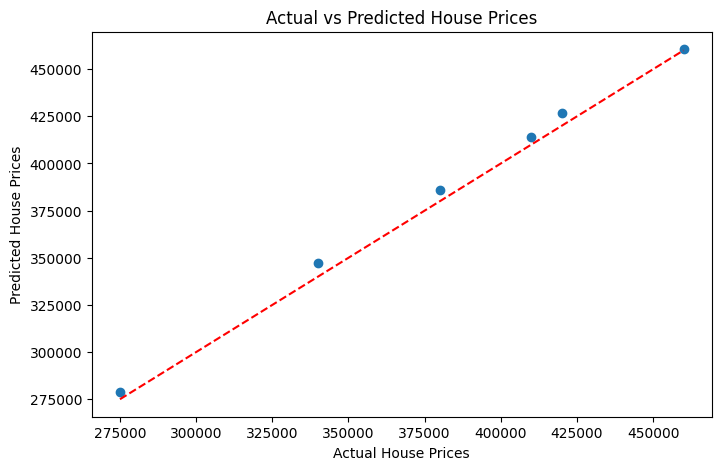


New House Details:
   SquareFeet  Bedrooms  Bathrooms
0        2000         3          2
Predicted House Price: $ 285494.06

Model Coefficients:
SquareFeet : 130.29
Bedrooms : 1780.28
Bathrooms : 7591.17


In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

data = {
    "SquareFeet": [1000, 1200, 1500, 1800, 2000, 2200, 2500, 2800, 3000, 3200,
                   1100, 1400, 1600, 1900, 2100, 2400, 2600, 2900, 3100, 3300,
                   1300, 1700, 2300, 2700, 3500, 3600, 1250, 1950, 2450, 3050],
    "Bedrooms": [2, 2, 3, 3, 3, 4, 4, 4, 5, 5,
                 2, 3, 3, 3, 4, 4, 4, 5, 5, 5,
                 2, 3, 4, 4, 5, 5, 2, 3, 4, 5],
    "Bathrooms": [1, 1, 2, 2, 2, 2, 3, 3, 3, 4,
                  1, 2, 2, 2, 2, 3, 3, 3, 4, 4,
                  1, 2, 2, 3, 4, 4, 1, 2, 3, 4],
    "Price": [150000, 180000, 220000, 260000, 280000, 310000, 350000, 390000, 420000, 460000,
              160000, 210000, 230000, 270000, 300000, 340000, 370000, 410000, 440000, 480000,
              190000, 240000, 330000, 380000, 500000, 520000, 175000, 275000, 360000, 450000]
}

df = pd.DataFrame(data)

X = df[["SquareFeet", "Bedrooms", "Bathrooms"]]
y = df["Price"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("HOUSE PRICE PREDICTION USING LINEAR REGRESSION")
print("------------------------------------------------")
print("Mean Absolute Error:", round(mean_absolute_error(y_test, y_pred), 2))
print("Mean Squared Error:", round(mean_squared_error(y_test, y_pred), 2))
print("Root Mean Squared Error:", round(np.sqrt(mean_squared_error(y_test, y_pred)), 2))
print("R2 Score:", round(r2_score(y_test, y_pred), 4))

plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_pred)
plt.xlabel("Actual House Prices")
plt.ylabel("Predicted House Prices")
plt.title("Actual vs Predicted House Prices")
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--")
plt.show()

new_house = pd.DataFrame({
    "SquareFeet": [2000],
    "Bedrooms": [3],
    "Bathrooms": [2]
})

predicted_price = model.predict(new_house)

print("\nNew House Details:")
print(new_house)
print("Predicted House Price: $", round(predicted_price[0], 2))

print("\nModel Coefficients:")
for feature, coefficient in zip(X.columns, model.coef_):
    print(feature, ":", round(coefficient, 2))
